# Baseline #
Naive forecast: consumption in the same hour one week earlier (`consumption_7days_ago`). Every model must beat this benchmark.

In [1]:
import pandas as pd
from pathlib import Path
from sklearn.metrics import mean_absolute_error

In [2]:
DATA_DIR = Path("../data")
df = pd.read_csv(DATA_DIR / "dataset.csv", parse_dates=["date"])
BASELINE="consumption_6days_ago"

In [3]:
#Same test period as xgboost.ipynb so the MAE values are comparable; the baseline needs no training data
cutoff = pd.to_datetime("2023-02-01")
test = df[df["date"] >= cutoff].dropna(subset=[BASELINE])

In [4]:
mae = mean_absolute_error(test["consumption"], test[BASELINE])
print("Naive 6d MAE:", mae, "MWH")
#MAE% (nMAE): MAE relative to mean consumption, so locations of different size can be compared
print("Naive 6d MAE%:", 100 * mae / test["consumption"].mean())

#MAE and error in percent of consumption, per location
errors = test.assign(err=(test["consumption"] - test[BASELINE]).abs())
per_location = errors.groupby("location").agg(mae=("err", "mean"), mean_consumption=("consumption", "mean"))
per_location["mae_pct"] = 100 * per_location["mae"] / per_location["mean_consumption"]
per_location

Naive 6d MAE: 0.47465593962789876 MWH
Naive 6d MAE%: 8.733422393244162


,mae,mean_consumption,mae_pct
location,,,
bergen,0.333619,3.176481,10.502772
helsingfors,0.149643,6.409953,2.334534
oslo,1.209258,11.940369,10.127476
stavanger,0.534940,5.517824,9.694770
tromsø,0.198149,1.942107,10.202784
trondheim,0.422550,3.622217,11.665497


oslo 2023-02-06 to 2023-02-19: MAE 1.277 MW, nMAE 10.5 %


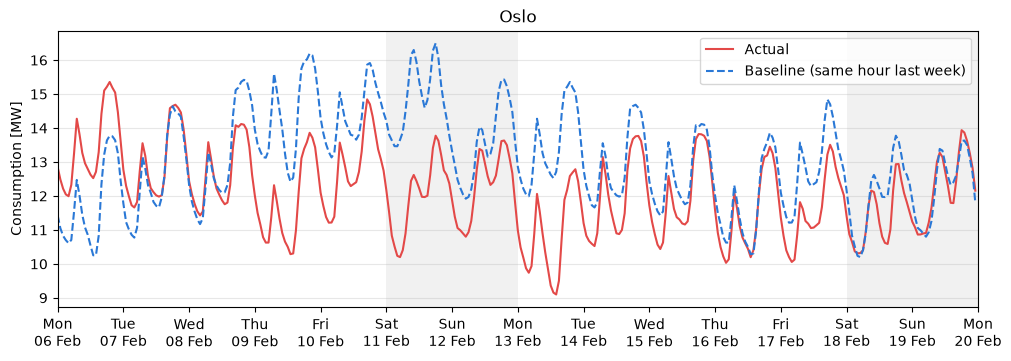

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from forecast_checks import TIMEZONES, DEFAULT_TIMEZONE

#Baseline forecast against actual consumption for one location; 6-19 Feb 2023 are two full weeks in the test period
LOCATION = "oslo"
START, END = "2023-02-06", "2023-02-19"     #local dates, inclusive

period = df[(df["location"] == LOCATION) & df["date"].between(START, END)]
#Local time, so the days on the x-axis are the calendar days the forecast is made for
local_time = pd.to_datetime(period["time"], utc=True).dt.tz_convert(TIMEZONES.get(LOCATION, DEFAULT_TIMEZONE)).dt.tz_localize(None)
error = (period["consumption"] - period[BASELINE]).abs()
print(f"{LOCATION} {START} to {END}: MAE {error.mean():.3f} MW, nMAE {100 * error.sum() / period['consumption'].sum():.1f} %")

fig, ax = plt.subplots(figsize=(10, 3.5), layout="constrained")
#Grey background on weekends
for day in period.loc[period["weekend"], "date"].unique():
    ax.axvspan(day, day + pd.Timedelta(days=1), color="#52514e", alpha=0.08, linewidth=0)
ax.plot(local_time, period["consumption"], color="#e34948", linewidth=1.5, label="Actual")
ax.plot(local_time, period["consumption_7days_ago"], color="#2a78d6", linewidth=1.5, linestyle="--",
        label="Baseline (same hour last week)")
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a\n%d %b"))
ax.margins(x=0)
ax.set_title(LOCATION.capitalize())
ax.set_ylabel("Consumption [MW]")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper right")
fig.savefig("results/baseline_vs_actual.pdf")
plt.show()